# Predicting Life Expectancy from Development Indicators

**Question:** How well can a country's development indicators predict its life expectancy, and which ones matter most?

**Data:** WHO Life Expectancy dataset (Kaggle), 183 countries, 2000–2015, cleaned with the pipeline in `src/data_prep.py`.

**The twist: target leakage.** Life expectancy is *calculated from* a country's death rates. A model given mortality indicators (adult mortality, child deaths, HIV/AIDS deaths) is partly reading the answer from its inputs. This notebook trains two versions and compares them:

- **Main model:** development indicators only (schooling, income, health spending, immunisation, nutrition, alcohol, development status).
- **Leakage comparison:** the same indicators **plus** the mortality variables.

Every model is tested on **countries it has never seen**, so the scores reflect how well it would work for a new country.

<a href="https://colab.research.google.com/github/ekoudavid/life-expectancy-prediction/blob/main/notebooks/life_expectancy_modelling.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup
When the notebook runs in Google Colab, this cell downloads the project files (data and cleaning code) from GitHub. When it runs locally from the repo, it uses the files already there.

In [1]:
import os, sys

REPO_URL = "https://github.com/ekoudavid/life-expectancy-prediction.git"

# Find the project folder: either we are inside the repo already, or (in Colab) we clone it
if os.path.exists("src/data_prep.py"):
    PROJECT_DIR = "."
elif os.path.exists("../src/data_prep.py"):
    PROJECT_DIR = ".."
else:
    os.system(f"git clone -q {REPO_URL} project")
    PROJECT_DIR = "project"

sys.path.insert(0, PROJECT_DIR)
DATA_PATH = os.path.join(PROJECT_DIR, "data", "Life Expectancy Data.csv")
FIG_DIR = os.path.join(PROJECT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("Project folder:", os.path.abspath(PROJECT_DIR))

Project folder: /home/claude/life-expectancy-ml


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from src.data_prep import load_raw, clean

RANDOM_STATE = 42   # fixed so every run gives the same results

# Chart style: one consistent look for every figure
BLUE, ORANGE, GREEN, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()

## 1. Load and clean the data
The cleaning pipeline (`src/data_prep.py`) fixes column names, removes 10 countries with a single year of data, sets impossible values to missing, drops four unreliable columns, and fills gaps **within each country** from its neighbouring years.

Two settings differ from the exploratory analysis:
- `fix_alcohol_placeholders=True`: many 2012–2015 rows record alcohol as exactly 0.01 litres, even for countries that drank around 10 litres a year before (Uganda drops from 10.2 to 0.01 in 2012). In countries whose typical consumption is above 0.5 litres, these are treated as missing-value codes.
- `fill_group_median=False`: values still missing after within-country interpolation are **not** filled yet. They are filled inside each model's pipeline using **training countries only**, so no information from the test countries leaks into training.

In [3]:
df_raw = load_raw(DATA_PATH)
df, cleaning_log = clean(df_raw, fill_group_median=False, fix_alcohol_placeholders=True)

for step in cleaning_log:
    print("-", step)
print("\nRows:", len(df), "| Countries:", df["country"].nunique(), "| Years:", df["year"].min(), "-", df["year"].max())

- Standardised column names
- Removed 0 duplicate country-year rows
- Removed 10 countries with only one year of data
- Set 1015 impossible values to missing
- Set 150 alcohol placeholder values (0.01) to missing
- Dropped unreliable columns: population, bmi, percentage_expenditure, measles
- Interpolated within each country; 992 values still missing
- Added log10 versions of GDP and HIV/AIDS deaths

Rows: 2928 | Countries: 183 | Years: 2000 - 2015


## 2. Frame the problem
- **Target:** life expectancy at birth (years), one value per country per year.
- **Two feature sets** (the inputs the model sees):
  - `DEVELOPMENT`: indicators a government can measure and act on, with no death rates.
  - `WITH_MORTALITY`: the same plus adult mortality, under-five and infant deaths, and HIV/AIDS deaths, which are ingredients of the life expectancy calculation itself.
- **Groups:** each country appears 16 times (once per year). Rows from the same country are near-copies, so countries, not rows, are kept together when splitting data.

In [4]:
df["developed"] = (df["status"] == "Developed").astype(int)   # 1 = Developed, 0 = Developing

DEVELOPMENT = ["schooling", "income_composition_of_resources", "log_gdp", "total_expenditure",
               "alcohol", "hepatitis_b", "polio", "diphtheria", "thinness_10_19_years", "developed"]
MORTALITY = ["adult_mortality", "under_five_deaths", "infant_deaths", "log_hiv_aids"]
WITH_MORTALITY = DEVELOPMENT + MORTALITY

FEATURE_SETS = {"Development only (main)": DEVELOPMENT, "With mortality (leakage)": WITH_MORTALITY}

# Readable names for charts and tables
NICE = {"schooling": "Schooling", "income_composition_of_resources": "Income composition (HDI)",
        "log_gdp": "GDP per capita (log)", "total_expenditure": "Health spending (% of govt.)",
        "alcohol": "Alcohol consumption", "hepatitis_b": "Hepatitis B coverage", "polio": "Polio coverage",
        "diphtheria": "Diphtheria coverage", "thinness_10_19_years": "Thinness, ages 10-19",
        "developed": "Developed status", "adult_mortality": "Adult mortality",
        "under_five_deaths": "Under-five deaths", "infant_deaths": "Infant deaths",
        "log_hiv_aids": "HIV/AIDS deaths (log)"}

y = df["life_expectancy"]
groups = df["country"]
print("Missing values the model pipelines will fill:", int(df[WITH_MORTALITY].isnull().sum().sum()))

Missing values the model pipelines will fill: 960


## 3. Hold out test countries
20% of countries (37) are set aside as a **test set** and not touched until the final evaluation. The models are developed on the other 146 countries.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, y, groups))
train, test = df.iloc[train_idx], df.iloc[test_idx]

print("Training countries:", train["country"].nunique(), f"({len(train)} rows)")
print("Test countries:    ", test["country"].nunique(), f"({len(test)} rows)")
print("Test set Developed / Developing countries:",
      test.drop_duplicates("country")["status"].value_counts().to_dict())
assert set(train["country"]).isdisjoint(set(test["country"]))   # no country in both

Training countries: 146 (2336 rows)
Test countries:     37 (592 rows)
Test set Developed / Developing countries: {'Developing': 29, 'Developed': 8}


## 4. The models
Each model is a **pipeline**: missing values are filled with the training median, then the model is fitted. Because the filling is part of the pipeline, it only ever learns from training data.

| Model | Why it is included |
|---|---|
| Baseline (predict the average) | The score any real model must beat |
| Linear regression | Simple and fully explainable: one weight per indicator |
| Random forest | Many decision trees averaged; captures non-linear patterns |
| Gradient boosting | Trees built one after another, each fixing the last one's errors |

In [6]:
def make_models():
    return {
        "Baseline (average)": make_pipeline(SimpleImputer(strategy="median"), DummyRegressor(strategy="mean")),
        "Linear regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Random forest": make_pipeline(SimpleImputer(strategy="median"),
                                       RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                             random_state=RANDOM_STATE, n_jobs=-1)),
        "Gradient boosting": make_pipeline(SimpleImputer(strategy="median"),
                                           HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

## 5. Cross-validation on the training countries
Before touching the test set, each model is checked with **5-fold grouped cross-validation**: the 146 training countries are split into 5 groups, each model is trained on 4 and scored on the 5th, rotating 5 times. Reporting the average and spread (±) shows how stable each score is.

- **MAE**: average error in years (lower is better).
- **RMSE**: like MAE but punishes big misses more (lower is better).
- **R²**: share of the variation in life expectancy explained, 0 to 1 (higher is better).

In [7]:
cv = GroupKFold(n_splits=5)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

cv_rows = []
for set_name, features in FEATURE_SETS.items():
    for model_name, model in make_models().items():
        scores = cross_validate(model, train[features], train["life_expectancy"],
                                groups=train["country"], cv=cv, scoring=scoring)
        cv_rows.append({
            "Feature set": set_name, "Model": model_name,
            "MAE": f"{-scores['test_MAE'].mean():.2f} ± {scores['test_MAE'].std():.2f}",
            "RMSE": f"{-scores['test_RMSE'].mean():.2f} ± {scores['test_RMSE'].std():.2f}",
            "R²": f"{scores['test_R2'].mean():.3f} ± {scores['test_R2'].std():.3f}",
        })

cv_results = pd.DataFrame(cv_rows)
cv_results

,Feature set,Model,MAE,RMSE,R²
0,Development only (main),Baseline (average),7.72 ± 0.64,9.43 ± 0.99,-0.037 ± 0.038
1,Development only (main),Linear regression,3.49 ± 0.50,4.80 ± 0.86,0.714 ± 0.117
2,Development only (main),Random forest,3.13 ± 0.49,4.39 ± 0.71,0.768 ± 0.068
3,Development only (main),Gradient boosting,3.17 ± 0.51,4.43 ± 0.76,0.760 ± 0.077
4,With mortality (leakage),Baseline (average),7.72 ± 0.64,9.43 ± 0.99,-0.037 ± 0.038
5,With mortality (leakage),Linear regression,2.97 ± 0.46,5.11 ± 2.62,0.542 ± 0.590
6,With mortality (leakage),Random forest,2.02 ± 0.29,2.84 ± 0.47,0.901 ± 0.039
7,With mortality (leakage),Gradient boosting,2.07 ± 0.31,2.93 ± 0.45,0.896 ± 0.035


## 6. Final test: 37 countries never seen before
Each model is now trained on all 146 training countries and scored once on the 37 test countries.

In [8]:
test_rows, fitted = [], {}
for set_name, features in FEATURE_SETS.items():
    for model_name, model in make_models().items():
        model.fit(train[features], train["life_expectancy"])
        pred = model.predict(test[features])
        fitted[(set_name, model_name)] = model
        test_rows.append({"Feature set": set_name, "Model": model_name,
                          "MAE": mean_absolute_error(test["life_expectancy"], pred),
                          "RMSE": root_mean_squared_error(test["life_expectancy"], pred),
                          "R²": r2_score(test["life_expectancy"], pred)})

test_results = pd.DataFrame(test_rows)
test_results.round(3)

,Feature set,Model,MAE,RMSE,R²
0,Development only (main),Baseline (average),7.982,9.949,-0.059
1,Development only (main),Linear regression,3.892,5.358,0.693
2,Development only (main),Random forest,3.517,4.711,0.762
3,Development only (main),Gradient boosting,3.539,4.793,0.754
4,With mortality (leakage),Baseline (average),7.982,9.949,-0.059
5,With mortality (leakage),Linear regression,2.674,3.623,0.860
6,With mortality (leakage),Random forest,1.967,2.747,0.919
7,With mortality (leakage),Gradient boosting,1.926,2.618,0.927


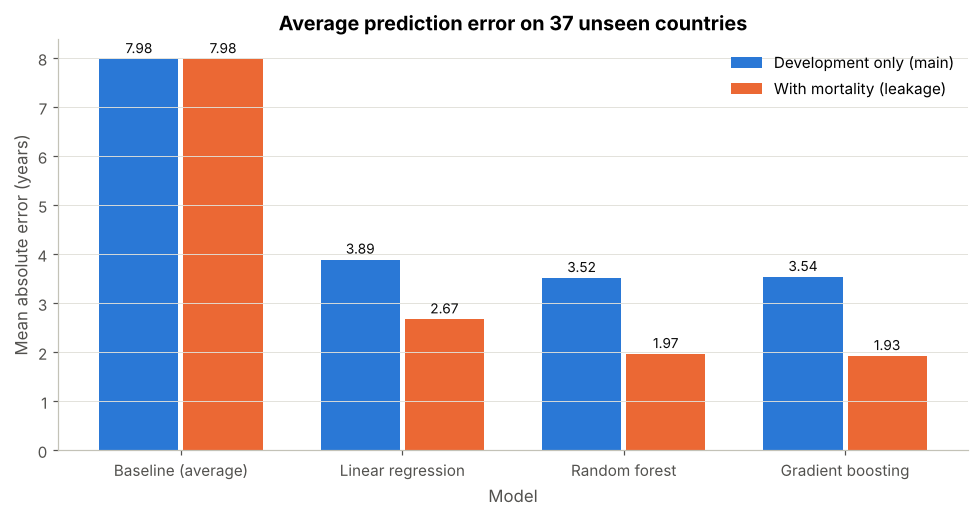

In [9]:
# Chart: test-set error for every model, main vs leakage version side by side
models_order = list(make_models().keys())
x = np.arange(len(models_order))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.8))
for k, (set_name, colour) in enumerate(zip(FEATURE_SETS, [BLUE, ORANGE])):
    vals = test_results[test_results["Feature set"] == set_name].set_index("Model").loc[models_order, "MAE"]
    bars = ax.bar(x + (k - 0.5) * width, vals.values, width=width * 0.94, color=colour, label=set_name)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.12, f"{v:.2f}", ha="center", color=INK, fontsize=9)

ax.set_xticks(x, models_order)
ax.set_title("Average prediction error on 37 unseen countries")
ax.set_xlabel("Model")
ax.set_ylabel("Mean absolute error (years)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
save(fig, "01_test_error_by_model")

## 7. What drives the main model's predictions?
**Permutation importance** asks: if one indicator's values were shuffled at random (breaking its link with life expectancy), how much worse would the predictions get? A big increase in error means the model relies heavily on that indicator. It is measured on the **test countries**, using the best main (development-only) model.

Best main model: Random forest


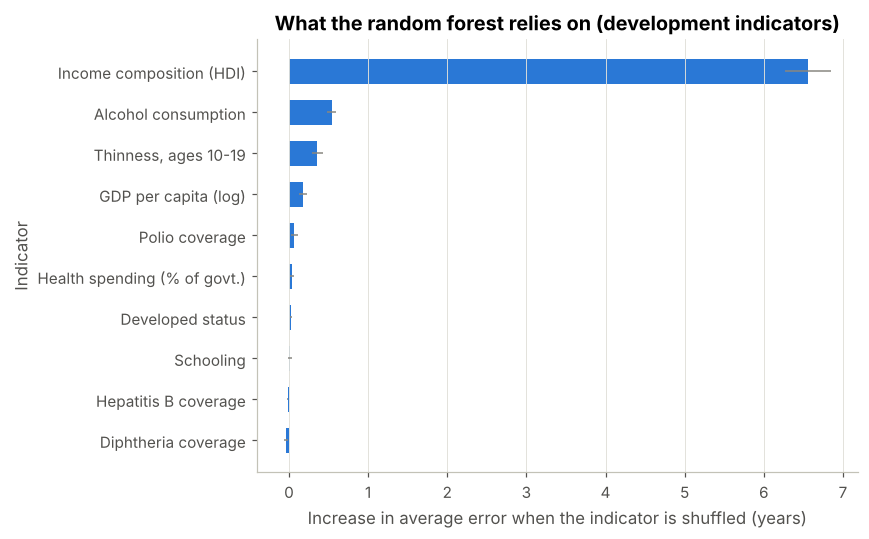

Income composition (HDI)        6.56
Alcohol consumption             0.54
Thinness, ages 10-19            0.36
GDP per capita (log)            0.18
Polio coverage                  0.06
Health spending (% of govt.)    0.04
Developed status                0.03
Schooling                       0.01
Hepatitis B coverage           -0.02
Diphtheria coverage            -0.04
dtype: float64

In [10]:
main_results = test_results[test_results["Feature set"] == "Development only (main)"]
best_main_name = main_results.sort_values("MAE").iloc[0]["Model"]
best_main = fitted[("Development only (main)", best_main_name)]
print("Best main model:", best_main_name)

perm = permutation_importance(best_main, test[DEVELOPMENT], test["life_expectancy"],
                              scoring="neg_mean_absolute_error", n_repeats=30, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=[NICE[f] for f in DEVELOPMENT]).sort_values()
spread = pd.Series(perm.importances_std, index=[NICE[f] for f in DEVELOPMENT]).loc[importance.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, xerr=spread.values, color=BLUE, height=0.6,
        error_kw={"ecolor": GREY, "elinewidth": 1})
ax.set_title(f"What the {best_main_name.lower()} relies on (development indicators)")
ax.set_xlabel("Increase in average error when the indicator is shuffled (years)")
ax.set_ylabel("Indicator")
ax.grid(axis="y", visible=False)
save(fig, "02_permutation_importance")
importance.sort_values(ascending=False).round(2)

## 8. Where does the main model go wrong?
Predicted vs actual life expectancy for every test country-year. Points on the diagonal are perfect predictions; the table lists the test countries with the largest average errors.

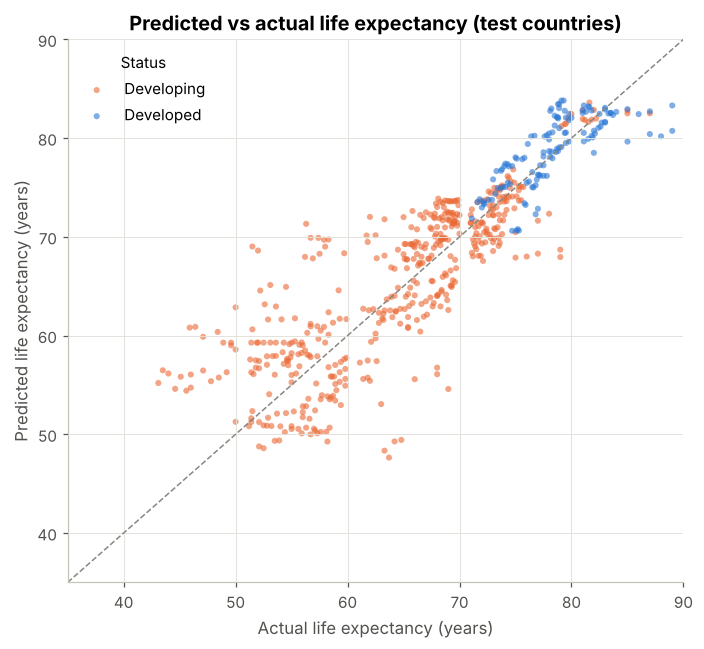

,mean_error,mean_absolute_error
country,,
United Republic of Tanzania,9.4,9.7
Malawi,8.4,8.4
Swaziland,6.3,8.3
Ethiopia,-6.6,6.6
Democratic Republic of the Congo,5.2,6.5
Gambia,-5.9,5.9
South Sudan,5.0,5.0
Bhutan,4.9,4.9


In [11]:
test_pred = test[["country", "year", "status", "life_expectancy"]].copy()
test_pred["predicted"] = best_main.predict(test[DEVELOPMENT])
test_pred["error"] = test_pred["predicted"] - test_pred["life_expectancy"]

fig, ax = plt.subplots(figsize=(6.5, 6))
for status, colour in [("Developing", ORANGE), ("Developed", BLUE)]:
    rows = test_pred[test_pred["status"] == status]
    ax.scatter(rows["life_expectancy"], rows["predicted"], s=16, alpha=0.6, color=colour, edgecolor="none", label=status)
lims = [35, 90]
ax.plot(lims, lims, color=GREY, linestyle="--", linewidth=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title("Predicted vs actual life expectancy (test countries)")
ax.set_xlabel("Actual life expectancy (years)")
ax.set_ylabel("Predicted life expectancy (years)")
ax.legend(title="Status", frameon=False)
save(fig, "03_predicted_vs_actual")

worst = (test_pred.groupby("country")["error"]
         .agg(mean_error="mean", mean_absolute_error=lambda e: e.abs().mean())
         .sort_values("mean_absolute_error", ascending=False).round(1))
worst.head(8)

## 9. Case study: Uganda
Uganda's life expectancy rose by about 16 years between 2000 and 2015, one of the largest gains of any Developing country, as HIV/AIDS deaths fell sharply. Can the main model, which never sees mortality data, reproduce this?

The model is retrained on **every country except Uganda**, then asked to predict Uganda's life expectancy each year from its development indicators alone.

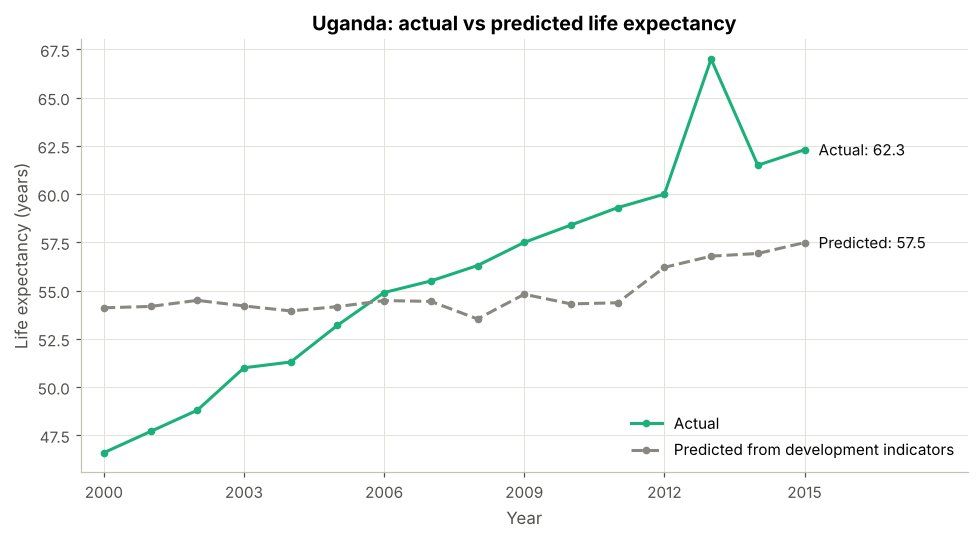

,actual,predicted,gap (actual - predicted)
year,,,
2000,46.6,54.1,-7.5
2005,53.2,54.2,-1.0
2010,58.4,54.3,4.1
2015,62.3,57.5,4.8


In [12]:
features = DEVELOPMENT
not_uganda = df[df["country"] != "Uganda"]
uganda = df[df["country"] == "Uganda"].sort_values("year")

uganda_model = make_models()[best_main_name]
uganda_model.fit(not_uganda[features], not_uganda["life_expectancy"])
uganda_pred = pd.Series(uganda_model.predict(uganda[features]), index=uganda["year"])
uganda_actual = uganda.set_index("year")["life_expectancy"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(uganda_actual.index, uganda_actual.values, color=GREEN, linewidth=2, marker="o", markersize=4, label="Actual")
ax.plot(uganda_pred.index, uganda_pred.values, color=GREY, linewidth=2, linestyle="--", marker="o", markersize=4,
        label="Predicted from development indicators")
for series, name in [(uganda_actual, "Actual"), (uganda_pred, "Predicted")]:
    ax.text(series.index[-1] + 0.3, series.values[-1], f"{name}: {series.values[-1]:.1f}", va="center", color=INK)
ax.set_xlim(1999.5, 2018.5)
ax.set_xticks(range(2000, 2016, 3))
ax.set_title("Uganda: actual vs predicted life expectancy")
ax.set_xlabel("Year")
ax.set_ylabel("Life expectancy (years)")
ax.legend(frameon=False, loc="lower right")
save(fig, "04_uganda_case_study")

summary = pd.DataFrame({"actual": uganda_actual, "predicted": uganda_pred.round(1)}).loc[[2000, 2005, 2010, 2015]]
summary["gap (actual - predicted)"] = (summary["actual"] - summary["predicted"]).round(1)
summary

## 10. Conclusions

**1. Development indicators alone predict life expectancy to within about 3.5 years.** On 37 countries the model never saw, the random forest using development indicators only had an average error of **3.52 years (R² 0.76)**, against 7.98 years for simply guessing the average. Cross-validation on the training countries gave a consistent 3.13 ± 0.49 years. The random forest and gradient boosting performed almost identically; both beat linear regression (3.89 years), which suggests some relationships are not straight lines.

**2. Adding mortality indicators looks better but is target leakage.** With adult mortality, child deaths and HIV/AIDS deaths included, the error falls to **1.93–1.97 years (R² about 0.92)**. This is not a better model: life expectancy is *calculated from* death rates, so these inputs partly contain the answer. The gap of roughly 1.5 years measures how much leakage inflates the scores. The development-only model is the one that answers the real question.

**3. Income composition dominates the main model.** Shuffling the income composition index raises the average error by about **6.6 years**, far more than any other indicator. Schooling scores near zero, but not because it does not matter: it is strongly linked to life expectancy (r = 0.77) and almost duplicates income composition (r = 0.92), so the model gets the same information from either. Permutation importance credits only one of two overlapping indicators.

**4. The largest errors are in countries with a heavy disease burden.** The model over-predicts life expectancy for the United Republic of Tanzania, Malawi, Swaziland and the Democratic Republic of the Congo: their development indicators suggest longer lives than people actually had. Several had very high HIV/AIDS mortality in the early 2000s, which development indicators do not capture. (Tanzania also has no income composition data at all, so the model relies on a filled-in value.) It under-predicts Ethiopia and Gambia, which did better than their development level suggests.

**5. Uganda's gain is not explained by development indicators.** Trained on every other country, the model predicts a nearly flat life expectancy of about 54 years for Uganda from 2000 to 2011, while actual life expectancy rose from 46.6 to 59.3. Uganda's development indicators changed little over that period, so the rise came from something the model cannot see. This is consistent with health-specific progress such as the scale-up of HIV testing and treatment, though this dataset cannot attribute it to any programme. (The isolated 2013 value of 67.0 is a probable data-recording error and is kept as reported.)

### Limitations
- **GDP is very noisy:** there are 953 year-to-year jumps of more than five-fold within countries (e.g. Uganda's 2002 GDP of about $24 per person), so its contribution should be read with caution.
- **Alcohol placeholders** were identified with a rule (0.01 litres in a country that typically drinks more than 0.5), not confirmed against the original source.
- **The data ends in 2015** and describes national averages; the results are associations, not causes, and may not apply to individuals.
- **One test split:** the cross-validation spread (±0.5 years) shows how much scores can vary with a different choice of test countries.

### Possible next steps
- Add **HIV prevalence and antiretroviral treatment coverage** (UNAIDS) as legitimate, non-leaking health indicators.
- Rebuild with **more recent WHO and World Bank data** (to 2021), including the COVID-19 period.
- Tune the tree models' settings and test whether the ranking of indicators holds.